In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score

import tensorflow as tf
from tensorflow import keras

import warnings 
warnings.filterwarnings('ignore')


In [45]:
# 1. قراءة البيانات وتنظيف القيم المفقودة
data = pd.read_csv(r'D:\w اكسل\L 20\Airline_Delay_Cause.csv')
data


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",136.0,7.0,5.95,0.00,...,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",91.0,16.0,7.38,0.00,...,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,9E,Endeavor Air Inc.,ACK,"Nantucket, MA: Nantucket Memorial",19.0,2.0,0.13,0.00,...,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",88.0,14.0,7.26,0.76,...,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",181.0,19.0,13.84,0.00,...,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318012,2003,6,DL,Delta Air Lines Inc.,SEA,"Seattle, WA: Seattle/Tacoma International",480.0,84.0,25.69,3.09,...,0.0,21.26,0.0,0.0,3744.0,978.0,164.0,1023.0,0.0,1579.0
318013,2003,6,DL,Delta Air Lines Inc.,SFO,"San Francisco, CA: San Francisco International",505.0,111.0,21.78,2.24,...,0.0,13.17,3.0,0.0,4284.0,1376.0,138.0,2132.0,0.0,638.0
318014,2003,6,DL,Delta Air Lines Inc.,SJC,"San Jose, CA: Norman Y. Mineta San Jose Intern...",146.0,36.0,6.99,0.00,...,0.0,2.15,0.0,0.0,896.0,205.0,0.0,607.0,0.0,84.0
318015,2003,6,DL,Delta Air Lines Inc.,SJU,"San Juan, PR: Luis Munoz Marin International",95.0,13.0,3.66,0.00,...,0.0,1.42,0.0,0.0,367.0,120.0,0.0,210.0,0.0,37.0


In [46]:
data.isna().sum()

year                     0
month                    0
carrier                  4
carrier_name             4
airport                  3
airport_name             0
arr_flights            493
arr_del15              732
carrier_ct             492
weather_ct             494
nas_ct                 488
security_ct            488
late_aircraft_ct       488
arr_cancelled          488
arr_diverted           490
arr_delay              494
carrier_delay          492
weather_delay          488
nas_delay              488
security_delay         490
late_aircraft_delay    488
dtype: int64

In [47]:
data.dropna(inplace=True)

In [48]:
data.isna().sum()

year                   0
month                  0
carrier                0
carrier_name           0
airport                0
airport_name           0
arr_flights            0
arr_del15              0
carrier_ct             0
weather_ct             0
nas_ct                 0
security_ct            0
late_aircraft_ct       0
arr_cancelled          0
arr_diverted           0
arr_delay              0
carrier_delay          0
weather_delay          0
nas_delay              0
security_delay         0
late_aircraft_delay    0
dtype: int64

In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 317261 entries, 0 to 318016
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 317261 non-null  int64  
 1   month                317261 non-null  int64  
 2   carrier              317261 non-null  object 
 3   carrier_name         317261 non-null  object 
 4   airport              317261 non-null  object 
 5   airport_name         317261 non-null  object 
 6   arr_flights          317261 non-null  float64
 7   arr_del15            317261 non-null  float64
 8   carrier_ct           317261 non-null  float64
 9   weather_ct           317261 non-null  float64
 10  nas_ct               317261 non-null  float64
 11  security_ct          317261 non-null  float64
 12  late_aircraft_ct     317261 non-null  float64
 13  arr_cancelled        317261 non-null  float64
 14  arr_diverted         317261 non-null  float64
 15  arr_delay            3

In [50]:
data.duplicated().sum()

np.int64(0)

In [51]:
data.drop(columns=['carrier_name', 'airport_name'], inplace=True)

In [52]:
X=data.drop(['arr_flights'],axis=1)
y=data['arr_flights']

In [55]:
X = pd.get_dummies(X, columns=['carrier', 'airport'], drop_first=True)

In [56]:
X

,year,month,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,...,airport_VLD,airport_VPS,airport_WRG,airport_WYS,airport_XNA,airport_XWA,airport_YAK,airport_YKM,airport_YNG,airport_YUM
0,2022,5,7.0,5.95,0.00,0.05,0.0,1.00,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
1,2022,5,16.0,7.38,0.00,2.54,0.0,6.09,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
2,2022,5,2.0,0.13,0.00,1.00,0.0,0.88,1.0,0.0,...,False,False,False,False,False,False,False,False,False,False
3,2022,5,14.0,7.26,0.76,4.35,0.0,1.64,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
4,2022,5,19.0,13.84,0.00,3.07,0.0,2.09,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318012,2003,6,84.0,25.69,3.09,33.96,0.0,21.26,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
318013,2003,6,111.0,21.78,2.24,73.81,0.0,13.17,3.0,0.0,...,False,False,False,False,False,False,False,False,False,False
318014,2003,6,36.0,6.99,0.00,26.85,0.0,2.15,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
318015,2003,6,13.0,3.66,0.00,7.92,0.0,1.42,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False


In [57]:
y

0          136.0
1           91.0
2           19.0
3           88.0
4          181.0
           ...  
318012     480.0
318013     505.0
318014     146.0
318015      95.0
318016    3466.0
Name: arr_flights, Length: 317261, dtype: float64

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, shuffle =True)

In [59]:
print('X_train shape is ' , X_train.shape)
print('X_test shape is ' , X_test.shape)
print('y_train shape is ' , y_train.shape)
print('y_test shape is ' , y_test.shape)

X_train shape is  (237945, 461)
X_test shape is  (79316, 461)
y_train shape is  (237945,)
y_test shape is  (79316,)


In [60]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [61]:
# 7. بناء نموذج الانحدار بالشبكة العصبية
model = keras.models.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.2),
    
    keras.layers.Dense(64, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.1),
    
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1, activation='linear') # خروج واحد بدون دالة تنشيط مخرجات غير خطية
])

In [62]:
# 8. تجميع النموذج (Compile)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
# 9. إعداد EarlyStopping مع استرجاع أفضل الأوزان
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

In [63]:
# 10. تدريب النموذج باستخدام البيانات المقيّسة (X_train_scaled)
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=150,
    batch_size=512,
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/150
465/465 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 772246.8125 - mae: 291.4128 - val_loss: 276496.3438 - val_mae: 203.6171
Epoch 2/150
465/465 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 144604.8906 - mae: 143.3710 - val_loss: 97419.2734 - val_mae: 113.8674
Epoch 3/150
465/465 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 94992.5078 - mae: 118.3091 - val_loss: 105195.3984 - val_mae: 106.0069
Epoch 4/150
465/465 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 83144.8438 - mae: 113.2621 - val_loss: 83046.0703 - val_mae: 101.2952
Epoch 5/150
465/465 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 70738.1562 - mae: 106.9279 - val_loss: 70412.1562 - val_mae: 93.3255
Epoch 6/150
465/465 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 62801.4375 - mae: 104.2192 - val_loss: 37945.2617 - val_mae: 79.6396
Epoch 7/150
465/465 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 57057.7031 - mae: 100.8444 - val_loss: 36127.4258 - val_mae: 75.7041
Epoch 8/150
465/465 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 53042.8047 - mae: 

In [64]:
print(kerasmodel.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 28,925 (112.99 KB)

 Trainable params: 9,641 (37.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,284 (75.33 KB)

None


In [65]:
y_predict = model.predict(X_test_scaled).flatten()

2479/2479 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step


In [66]:
print(y_predict.shape)

(79316,)


In [67]:
print(format(y_predict[:5]))

[894.8107  231.11435 105.00555 107.1695   29.00386]


In [68]:
y_test[:5]

275895    816.0
119384    290.0
117327    116.0
53842     175.0
153312     58.0
Name: arr_flights, dtype: float64

In [70]:
# 12. التقييم الدقيق باستخدام مقاييس الانحدار
mae = mean_absolute_error(y_test, y_predict)
mse = mean_squared_error(y_test, y_predict)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_predict)

In [71]:
print("\n--- نتائج التقييم المحسّنة (Regression Metrics) ---")
print(f"Mean Absolute Error (MAE)   : {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R2 Score                    : {r2:.4f}")


--- نتائج التقييم المحسّنة (Regression Metrics) ---
Mean Absolute Error (MAE)   : 57.01
Root Mean Squared Error (RMSE): 138.99
R2 Score                    : 0.9821


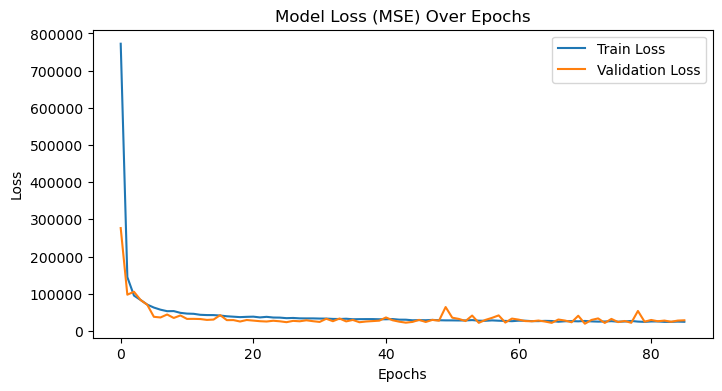

In [73]:
# رسم دالة الخسارة أثناء التدريب
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss (MSE) Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()